# ======================================
# ***Machine Learning Project Notebook***
# ======================================
# Author: juma
# Date:
# Project:Medical Insurance Cost Prediction
# ======================================


## 📌 0️⃣ Orientation (Revised)

**Dataset name**: *Medical Insurance Cost*
**Source**: *Kaggle*

# Real-world context:
- *This project focuses on building a predictive model to estimate medical insurance costs for patients based on personal and health-related attributes.*

# Why this problem is interesting:
- *This is a real-world problem with practical impact. An accurate prediction model can help reduce bias in insurance premium pricing, minimize favoritism and corruption, and support fair, data-driven decision-making.*
- *It can also improve efficiency by reducing the time required to assess insurance costs manually.*

## 🎯 Purpose (Revised)

# Purpose of this project:
 **The purpose of this project is to:**

- *Develop a strong understanding of Linear Regression*

- *Strengthen data analysis and data preparation skills*

- *Learn and apply different techniques for improving model accuracy*

- *Understand how model assumptions and data quality affect predictions*


In [ ]:
# Fixing the tuple column creation issue from the mapping step
# Dropping any tuple columns that were unintentionally added to the DataFrame
tuple_cols = [col for col in data.columns if isinstance(col, tuple)]
if tuple_cols:
    data = data.drop(columns=tuple_cols)
    print(f"Cleaned up {len(tuple_cols)} tuple-based label columns to ensure clean model encoding.")

# Importing the nessesary libraries

In [ ]:
from sklearn.preprocessing import StandardScaler,Normalizer,Binarizer,OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
from sklearn.compose import ColumnTransformer
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

In [ ]:
# Loading the dataset
data = pd.read_csv('/content/medical_insurance.csv')

In [ ]:
# Printing the first 5 rows
data.head()

,person_id,age,sex,region,urban_rural,income,education,marital_status,employment_status,household_size,...,liver_disease,arthritis,mental_health,proc_imaging_count,proc_surgery_count,proc_physio_count,proc_consult_count,proc_lab_count,is_high_risk,had_major_procedure
0,75722,52,Female,North,Suburban,22700.0,Doctorate,Married,Retired,3,...,0,1,0,1,0,2,0,1,0,0
1,80185,79,Female,North,Urban,12800.0,No HS,Married,Employed,3,...,0,1,1,0,0,1,0,1,1,0
2,19865,68,Male,North,Rural,40700.0,HS,Married,Retired,5,...,0,0,1,1,0,2,1,0,1,0
3,76700,15,Male,North,Suburban,15600.0,Some College,Married,Self-employed,5,...,0,0,0,1,0,0,1,0,0,0
4,92992,53,Male,Central,Suburban,89600.0,Doctorate,Married,Self-employed,2,...,0,1,0,2,0,1,1,0,1,0


# 2️⃣ Understand the Data Structu

In [ ]:
data.columns

Index(['person_id', 'age', 'sex', 'region', 'urban_rural', 'income',
       'education', 'marital_status', 'employment_status', 'household_size',
       'dependents', 'bmi', 'smoker', 'alcohol_freq', 'visits_last_year',
       'hospitalizations_last_3yrs', 'days_hospitalized_last_3yrs',
       'medication_count', 'systolic_bp', 'diastolic_bp', 'ldl', 'hba1c',
       'plan_type', 'network_tier', 'deductible', 'copay', 'policy_term_years',
       'policy_changes_last_2yrs', 'provider_quality', 'risk_score',
       'annual_medical_cost', 'annual_premium', 'monthly_premium',
       'claims_count', 'avg_claim_amount', 'total_claims_paid',
       'chronic_count', 'hypertension', 'diabetes', 'asthma', 'copd',
       'cardiovascular_disease', 'cancer_history', 'kidney_disease',
       'liver_disease', 'arthritis', 'mental_health', 'proc_imaging_count',
       'proc_surgery_count', 'proc_physio_count', 'proc_consult_count',
       'proc_lab_count', 'is_high_risk', 'had_major_procedure'],
      

In [ ]:
data.shape

(100000, 54)

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 54 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   person_id                    100000 non-null  int64  
 1   age                          100000 non-null  int64  
 2   sex                          100000 non-null  object 
 3   region                       100000 non-null  object 
 4   urban_rural                  100000 non-null  object 
 5   income                       100000 non-null  float64
 6   education                    100000 non-null  object 
 7   marital_status               100000 non-null  object 
 8   employment_status            100000 non-null  object 
 9   household_size               100000 non-null  int64  
 10  dependents                   100000 non-null  int64  
 11  bmi                          100000 non-null  float64
 12  smoker                       100000 non-null  object 
 13  

In [ ]:
data['cancer_history']

,cancer_history
0,0
1,0
2,1
3,0
4,0
...,...
99995,0
99996,0
99997,0
99998,0


In [ ]:
def numeric_col(data):

    for col in data.columns:
        if data[col].dtype == 'object':
            coerced = pd.to_numeric(data[col], errors='coerce')
            bad_val = data[col][coerced.isna() & data[col].notna()]

            if not bad_val.empty:
                print(f"❌ {col} contains non-numeric values:")
                print(bad_val.unique()[:5])
numeric_col(data)

❌ sex contains non-numeric values:
['Female' 'Male' 'Other']
❌ region contains non-numeric values:
['North' 'Central' 'West' 'South' 'East']
❌ urban_rural contains non-numeric values:
['Suburban' 'Urban' 'Rural']
❌ education contains non-numeric values:
['Doctorate' 'No HS' 'HS' 'Some College' 'Masters']
❌ marital_status contains non-numeric values:
['Married' 'Single' 'Divorced' 'Widowed']
❌ employment_status contains non-numeric values:
['Retired' 'Employed' 'Self-employed' 'Unemployed']
❌ smoker contains non-numeric values:
['Never' 'Current' 'Former']
❌ alcohol_freq contains non-numeric values:
['Weekly' 'Daily' 'Occasional']
❌ plan_type contains non-numeric values:
['PPO' 'POS' 'HMO' 'EPO']
❌ network_tier contains non-numeric values:
['Bronze' 'Gold' 'Platinum' 'Silver']


In [ ]:
# Conferming data types for each categorical columns
def categorical_col(data):
    category = data.select_dtypes(include= 'object')
    for col in category.columns:
        first_val = category[col].iloc[0]
        print(f'{col}: {first_val} ({type(first_val)})')
    return data

categorical_col(data)


sex: Female (<class 'str'>)
region: North (<class 'str'>)
urban_rural: Suburban (<class 'str'>)
education: Doctorate (<class 'str'>)
marital_status: Married (<class 'str'>)
employment_status: Retired (<class 'str'>)
smoker: Never (<class 'str'>)
alcohol_freq: nan (<class 'float'>)
plan_type: PPO (<class 'str'>)
network_tier: Bronze (<class 'str'>)


,person_id,age,sex,region,urban_rural,income,education,marital_status,employment_status,household_size,...,liver_disease,arthritis,mental_health,proc_imaging_count,proc_surgery_count,proc_physio_count,proc_consult_count,proc_lab_count,is_high_risk,had_major_procedure
0,75722,52,Female,North,Suburban,22700.0,Doctorate,Married,Retired,3,...,0,1,0,1,0,2,0,1,0,0
1,80185,79,Female,North,Urban,12800.0,No HS,Married,Employed,3,...,0,1,1,0,0,1,0,1,1,0
2,19865,68,Male,North,Rural,40700.0,HS,Married,Retired,5,...,0,0,1,1,0,2,1,0,1,0
3,76700,15,Male,North,Suburban,15600.0,Some College,Married,Self-employed,5,...,0,0,0,1,0,0,1,0,0,0
4,92992,53,Male,Central,Suburban,89600.0,Doctorate,Married,Self-employed,2,...,0,1,0,2,0,1,1,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,6266,50,Male,West,Urban,127200.0,No HS,Married,Employed,2,...,0,0,0,0,0,1,0,0,0,0
99996,54887,42,Male,East,Suburban,21600.0,HS,Married,Employed,2,...,0,0,0,0,0,0,0,0,0,0
99997,76821,41,Male,West,Rural,81900.0,HS,Divorced,Unemployed,1,...,0,0,0,1,0,1,0,0,0,0
99998,861,51,Female,South,Urban,43400.0,Doctorate,Single,Unemployed,3,...,0,0,1,0,0,2,2,1,0,0


# **Data Preprocessing and Exploration**

# 1.**Data Cleaning**

In [ ]:
# Cheacking for missing values
data.isna().sum()

,0
person_id,0
age,0
sex,0
region,0
urban_rural,0
income,0
education,0
marital_status,0
employment_status,0
household_size,0


In [ ]:
# Filling the missing values using mode
mode = data['alcohol_freq'].mode()

if not mode.empty:
    data['alcohol_freq'] = data['alcohol_freq'].fillna(mode[0])

else:
    data['alcohol_freq'] = data['alcohol_freq'].fillna('unknown')

In [ ]:
# Checking for duplicates
data.duplicated().sum()

np.int64(0)

# 2.**Exploratory Data Analysis (EDA)**

In [ ]:
# Printing the columns
data.columns

Index(['person_id', 'age', 'sex', 'region', 'urban_rural', 'income',
       'education', 'marital_status', 'employment_status', 'household_size',
       'dependents', 'bmi', 'smoker', 'alcohol_freq', 'visits_last_year',
       'hospitalizations_last_3yrs', 'days_hospitalized_last_3yrs',
       'medication_count', 'systolic_bp', 'diastolic_bp', 'ldl', 'hba1c',
       'plan_type', 'network_tier', 'deductible', 'copay', 'policy_term_years',
       'policy_changes_last_2yrs', 'provider_quality', 'risk_score',
       'annual_medical_cost', 'annual_premium', 'monthly_premium',
       'claims_count', 'avg_claim_amount', 'total_claims_paid',
       'chronic_count', 'hypertension', 'diabetes', 'asthma', 'copd',
       'cardiovascular_disease', 'cancer_history', 'kidney_disease',
       'liver_disease', 'arthritis', 'mental_health', 'proc_imaging_count',
       'proc_surgery_count', 'proc_physio_count', 'proc_consult_count',
       'proc_lab_count', 'is_high_risk', 'had_major_procedure'],
      

# 2.1.Checking on the Distribution of annual_premium which is the target

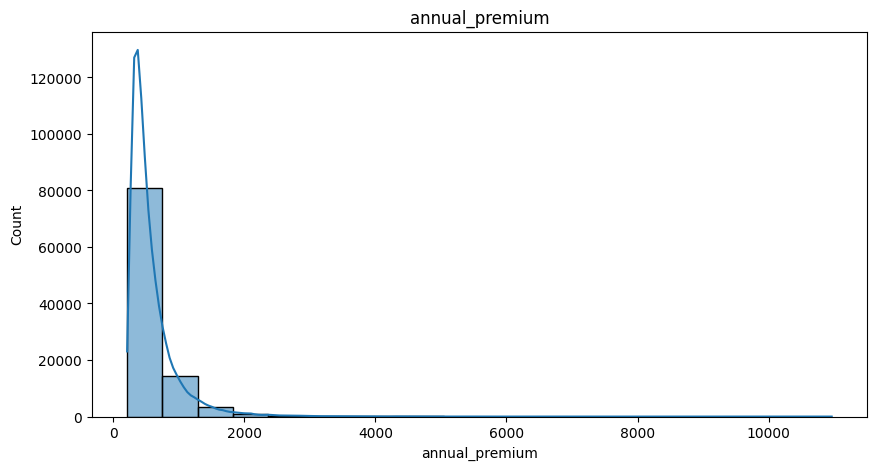

In [ ]:
# Plotting a Histogram plot for annual_premium
plt.figure(figsize=(10,5))
sns.histplot(data=data,x='annual_premium',bins=20,kde=True)

plt.xlabel('annual_premium')
plt.title('annual_premium')
plt.show()

# Insight: Target variable distribution
- The annual_premium target variable has a strongly right‑skewed distribution, with a long tail towards very high premium values.
​

- The majority of customers pay annual premiums concentrated roughly between 500 and 1 000, indicating this is the typical pricing band in the dataset.
​

- The distribution reveals several potential outliers at unusually high premium levels, which require further investigation to determine whether they are data‑entry errors or valid but rare high‑value policies.
​

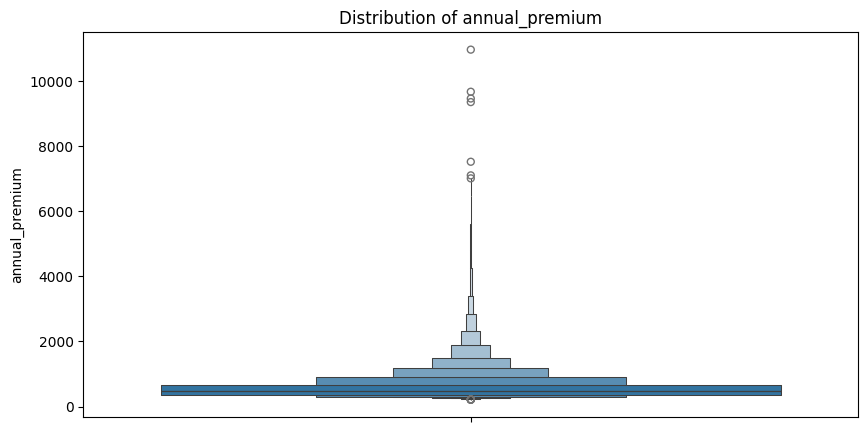

In [ ]:
# Plotting a box plot for annual_premium
plt.figure(figsize=(10,5))
sns.boxenplot(data=data,y='annual_premium')
plt.ylabel('annual_premium')
plt.title('Distribution of annual_premium')
plt.show()

- *The box plot of annual_premium confirms a strongly right‑skewed distribution, with the bulk of observations concentrated near the lower end of the scale and a long upper tail.*
​

- *Multiple data points appear as upper‑side outliers, far above the upper whisker, indicating a small group of customers with unusually high annual premiums compared to the rest of the portfolio.*
​

- *These high‑premium observations will be treated as candidate outliers for further investigation, to distinguish genuine high‑value policies from possible data‑entry issues before modeling*

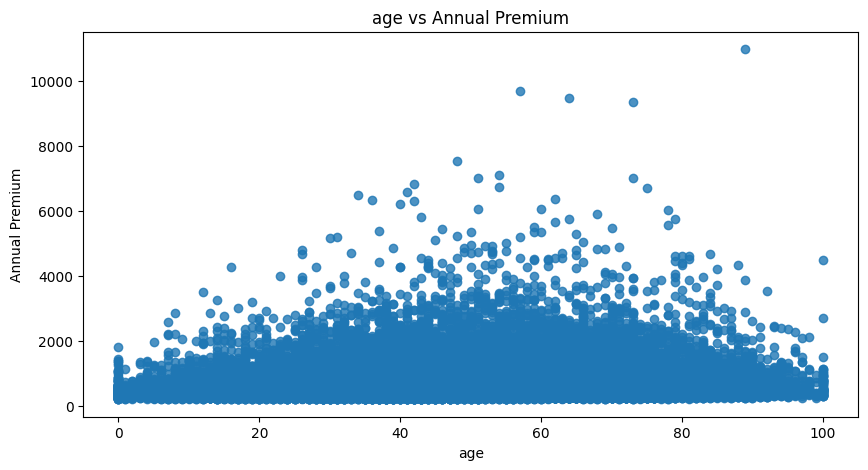

In [ ]:

plt.figure(figsize=(10,5))
sns.regplot(data=data, x= 'age', y='annual_premium')
plt.xlabel('age')
plt.ylabel('Annual Premium')
plt.title(f'age vs Annual Premium')
plt.show()

*Premiums vary widely at every age, and the fitted regression line is nearly flat, indicating that age alone has very little linear predictive power for annual premium. This suggests other factors (such as coverage type, vehicle value, claims history, or region) are needed to explain most of the variation in premium*.

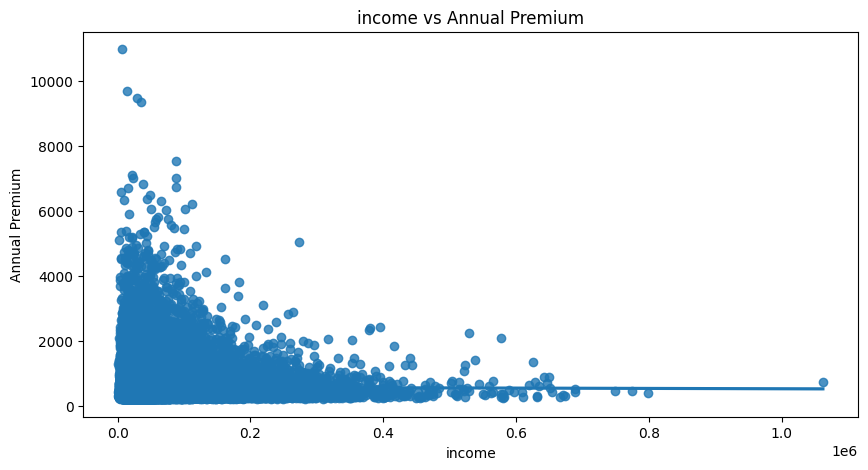

In [ ]:
plt.figure(figsize=(10,5))
sns.regplot(data=data,  x= 'income', y='annual_premium')
plt.xlabel('income')
plt.ylabel('Annual Premium')
plt.title(f'income vs Annual Premium')
plt.show()

*Income shows almost no linear association with annual premium. Premium amounts vary widely across all income levels, so income by itself is not sufficient to predict a customer’s annual premium; other factors must be driving most of the variation.*

In [ ]:
binary_col = [

    'hypertension',
    'diabetes',
    'asthma',
    'copd',
    'cardiovascular_disease',
    'cancer_history',
    'kidney_disease',
    'liver_disease',
    'arthritis',
    'mental_health',
    'is_high_risk',
    'had_major_procedure'

]

for col in binary_col:
    data[col,"_label"] = data[col].map({1:'yes',0:'no'})
    data[col] = data[col].astype('category')

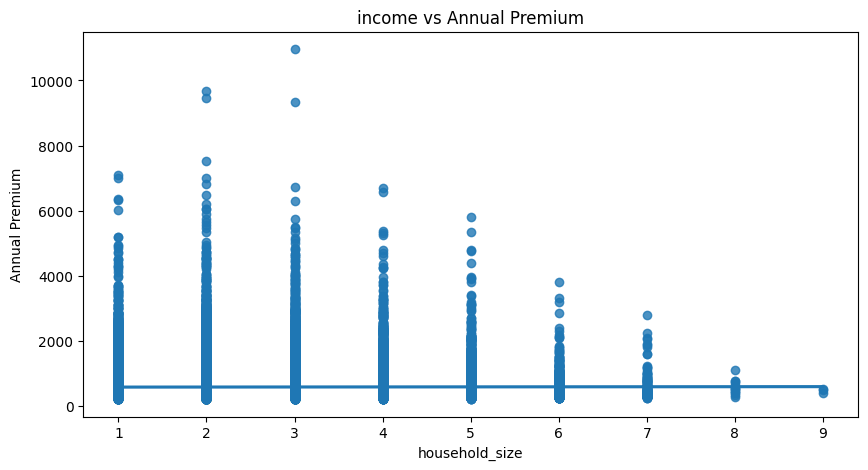

In [ ]:
plt.figure(figsize=(10,5))
sns.regplot(data=data,  x= 'household_size', y='annual_premium')
plt.xlabel('household_size')
plt.ylabel('Annual Premium')
plt.title(f'income vs Annual Premium')
plt.show()

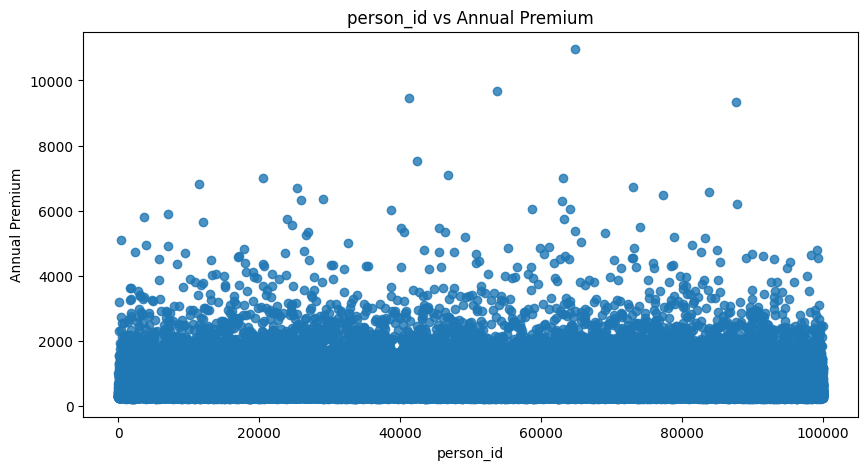

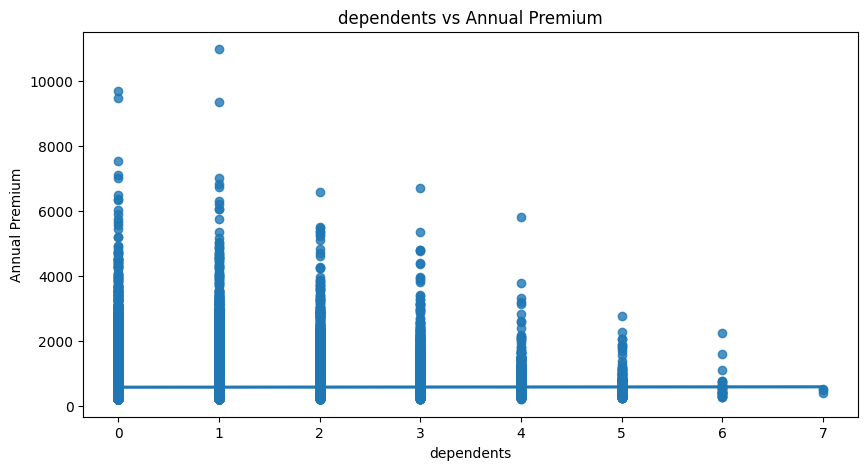

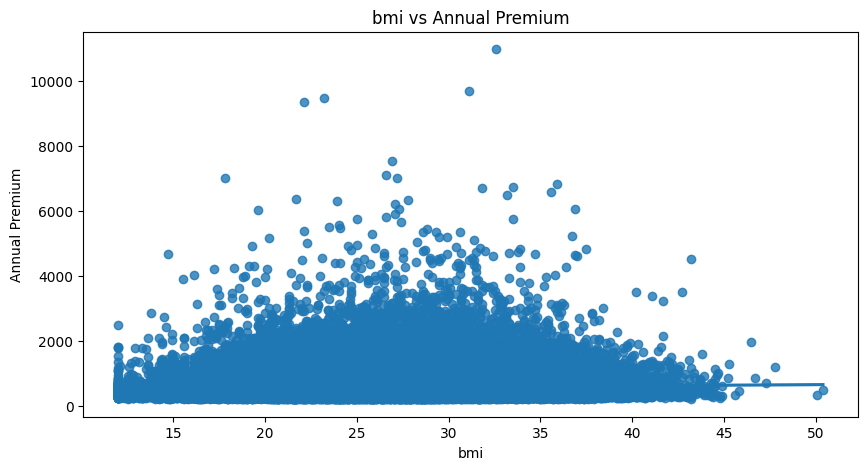

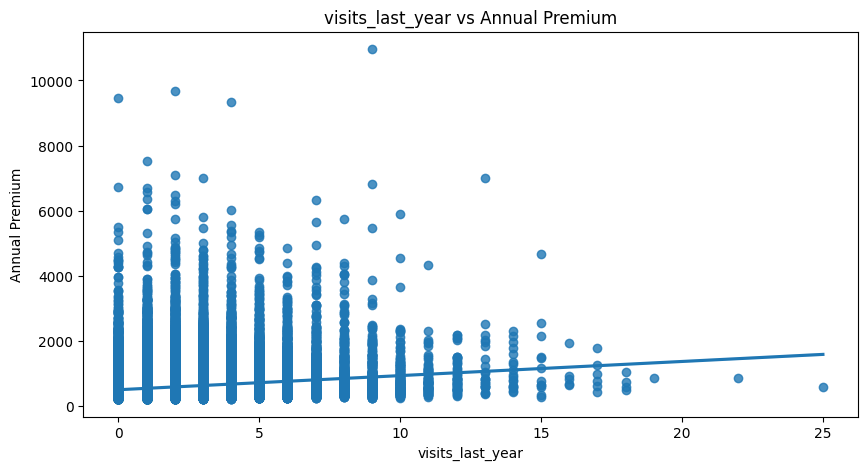

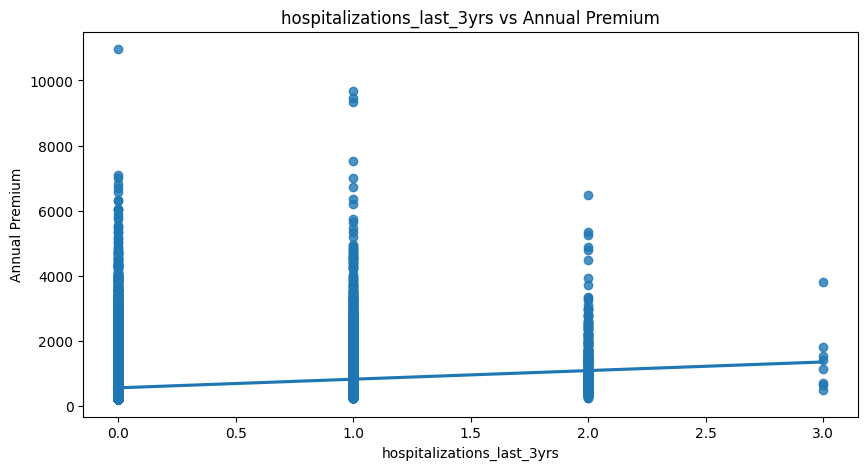

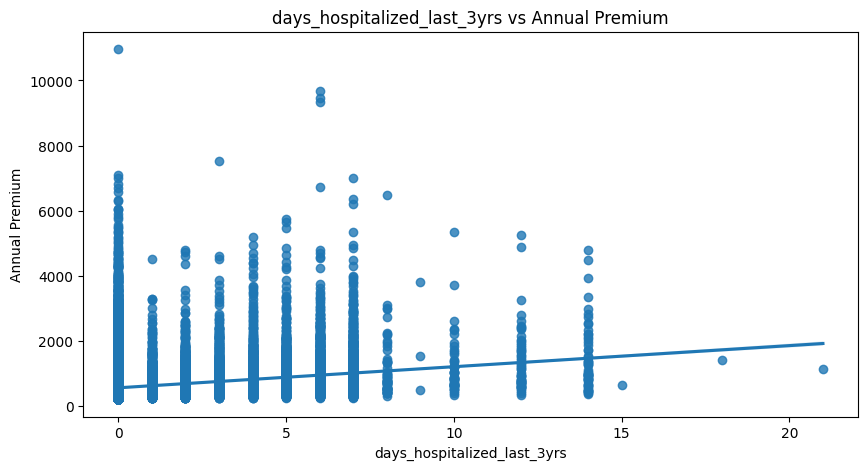

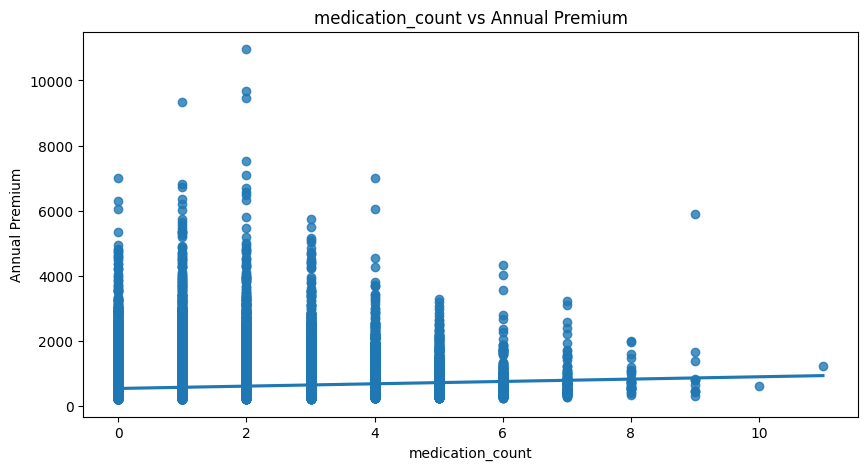

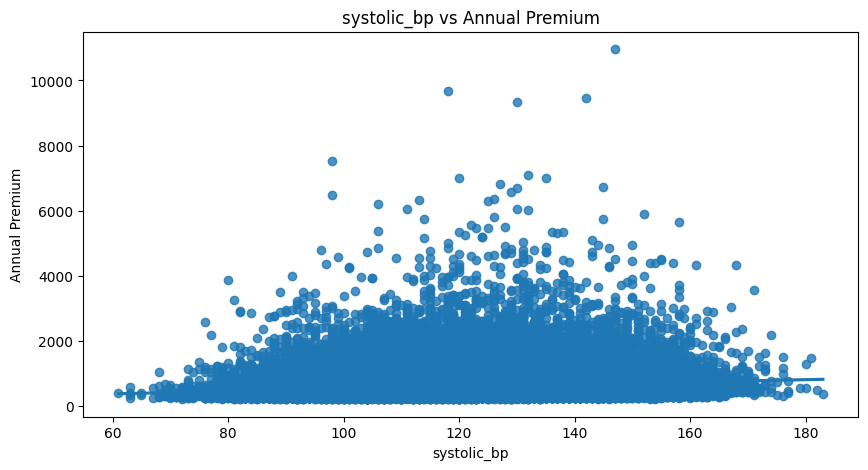

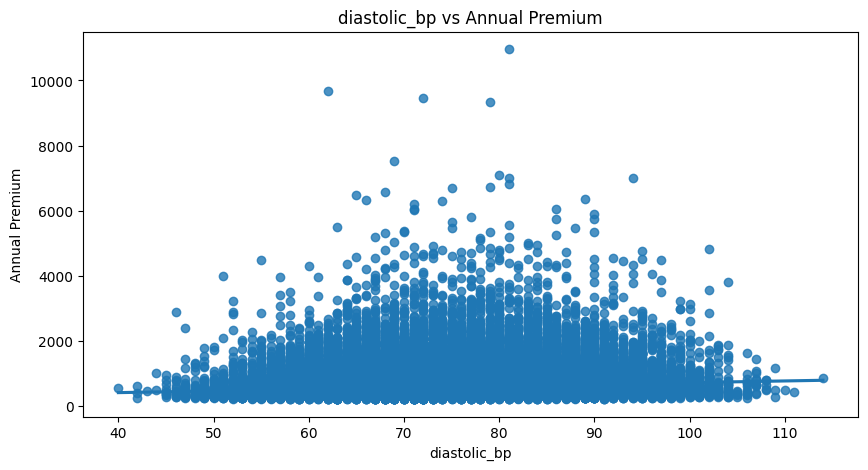

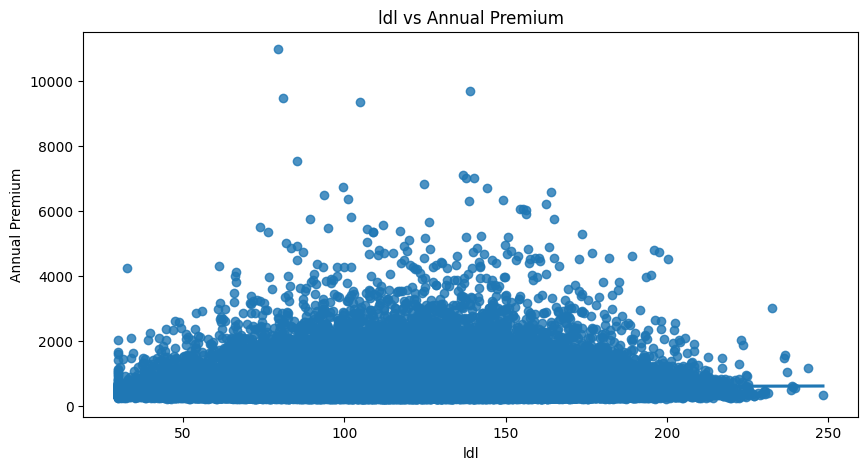

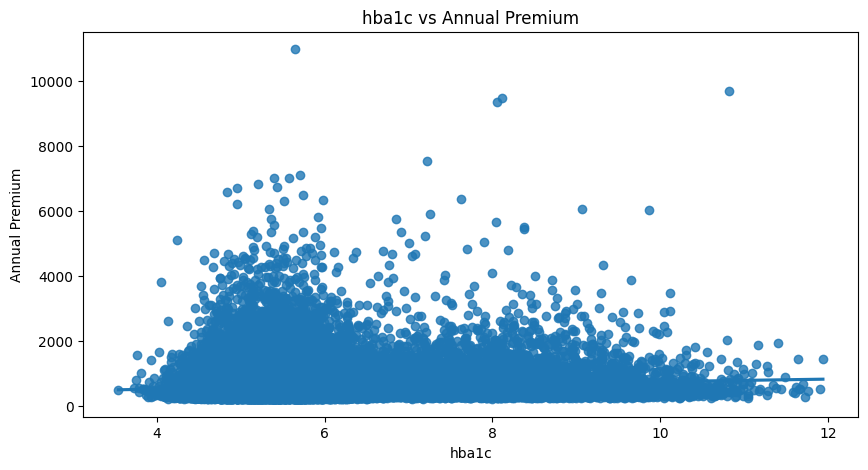

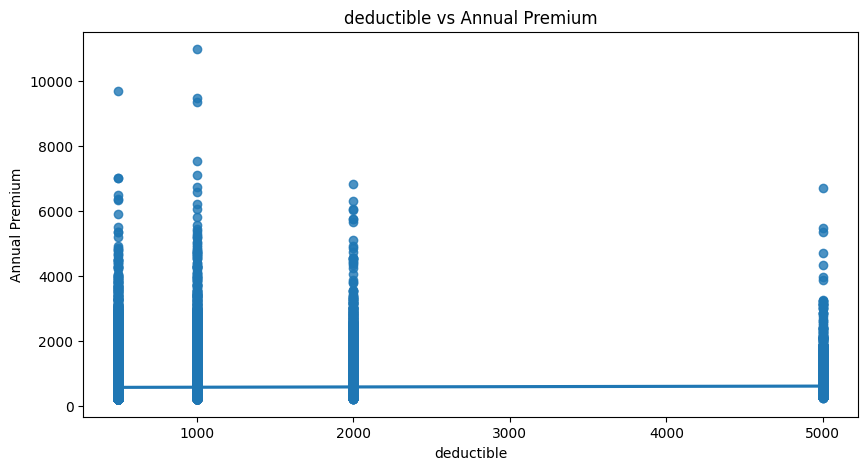

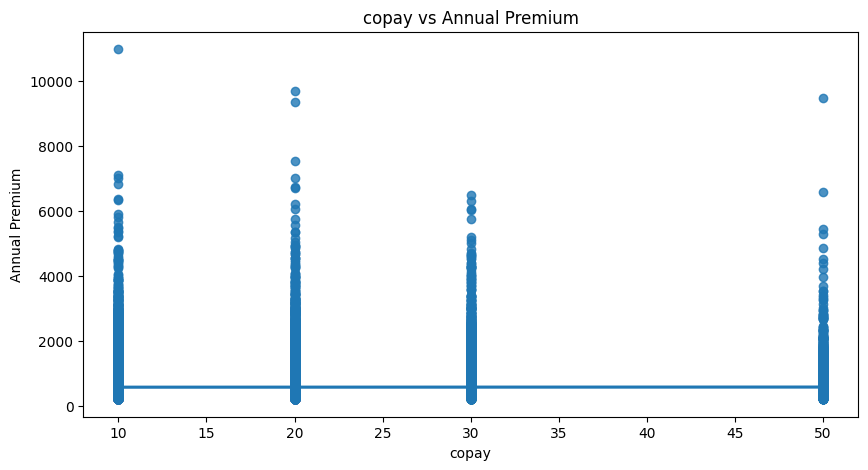

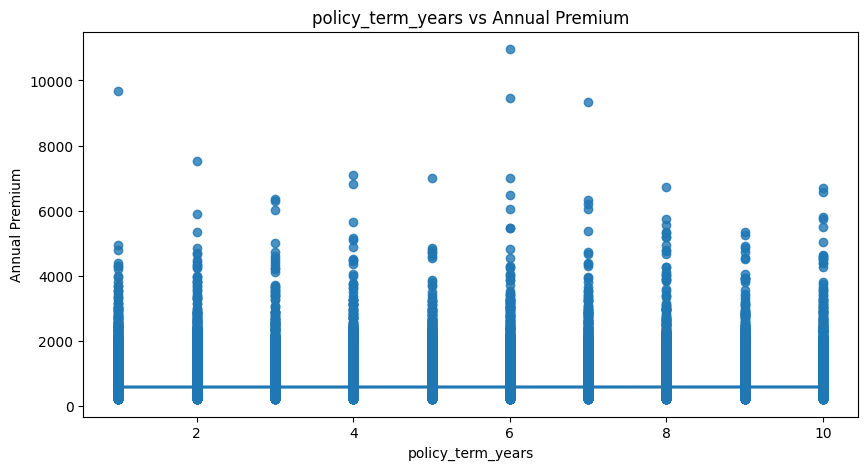

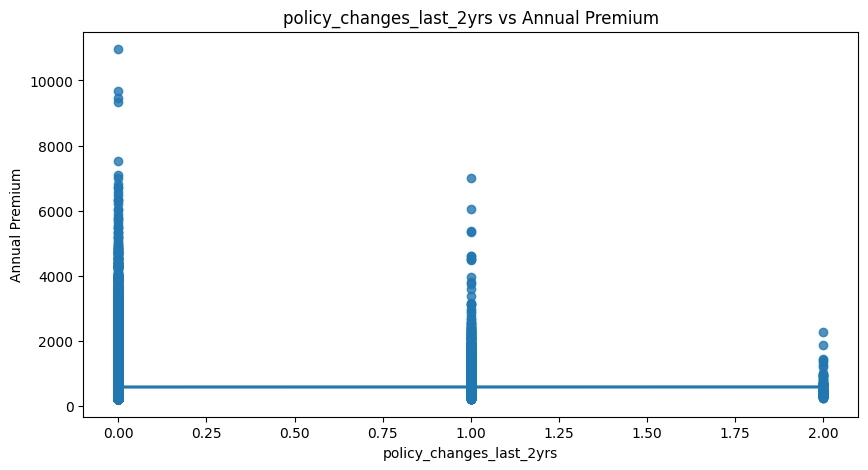

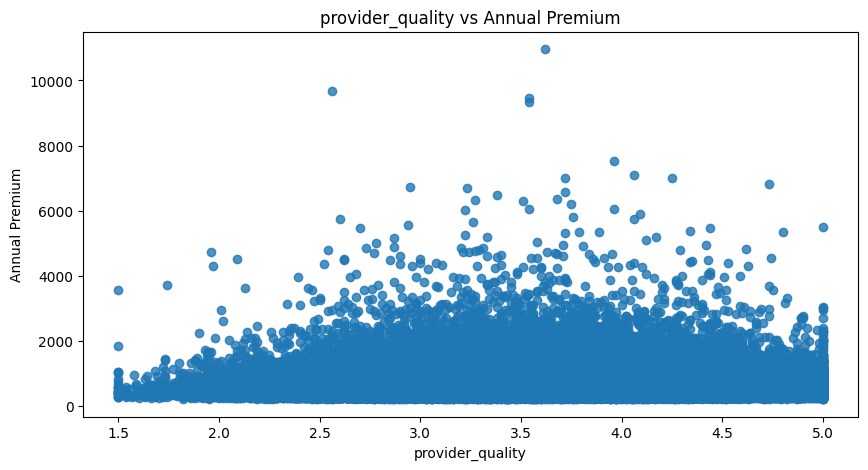

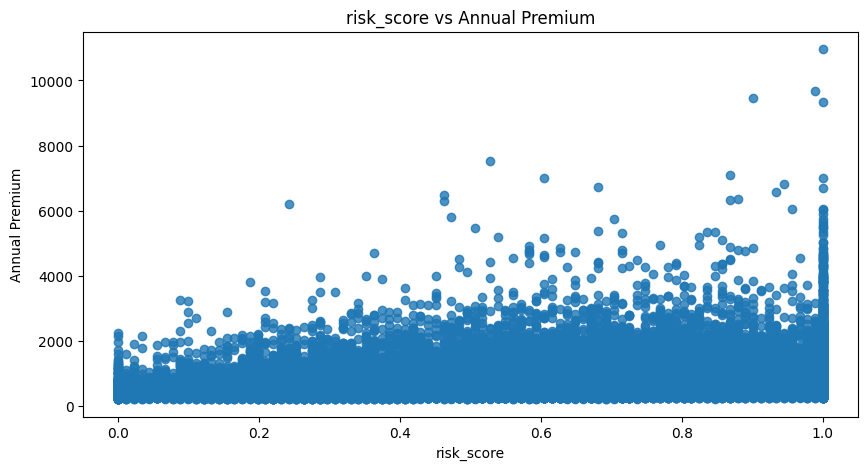

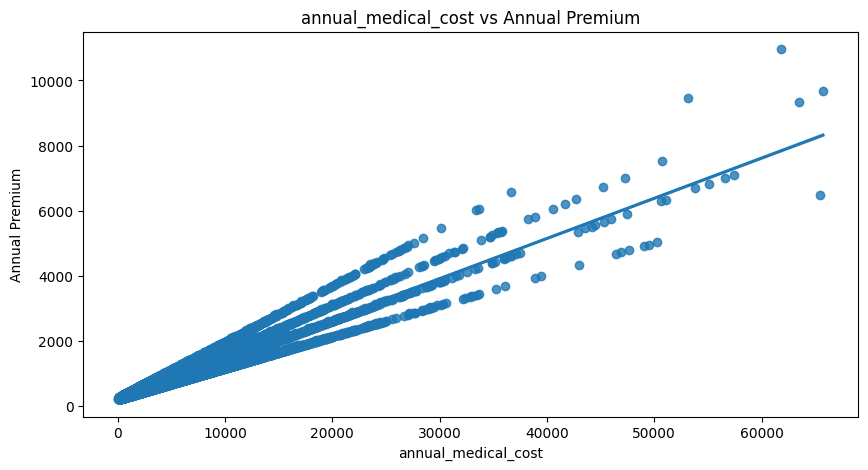

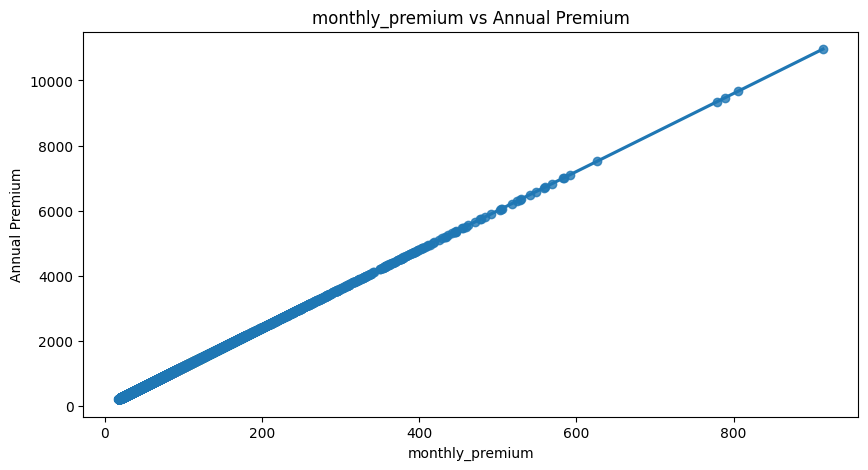

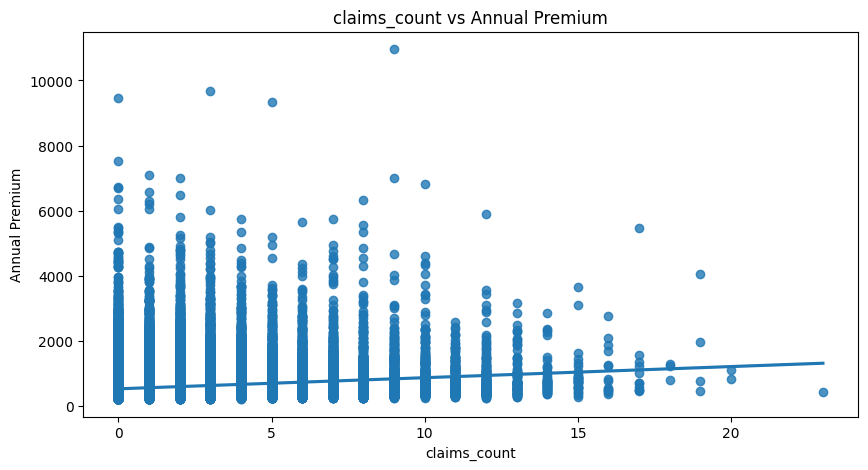

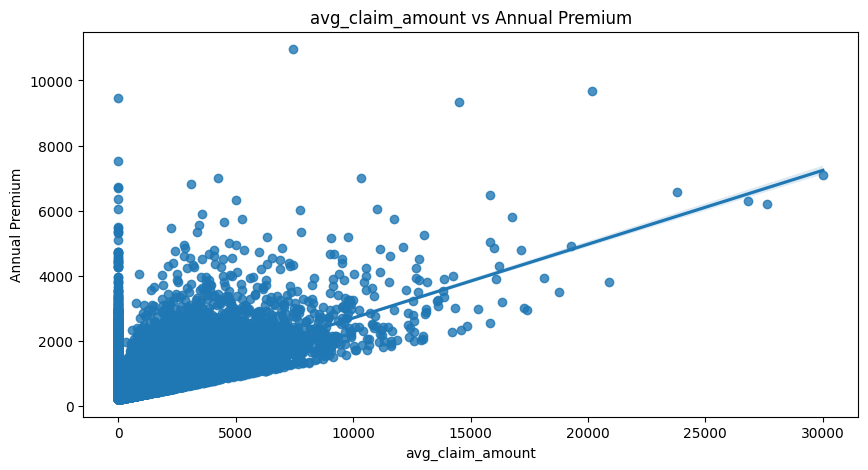

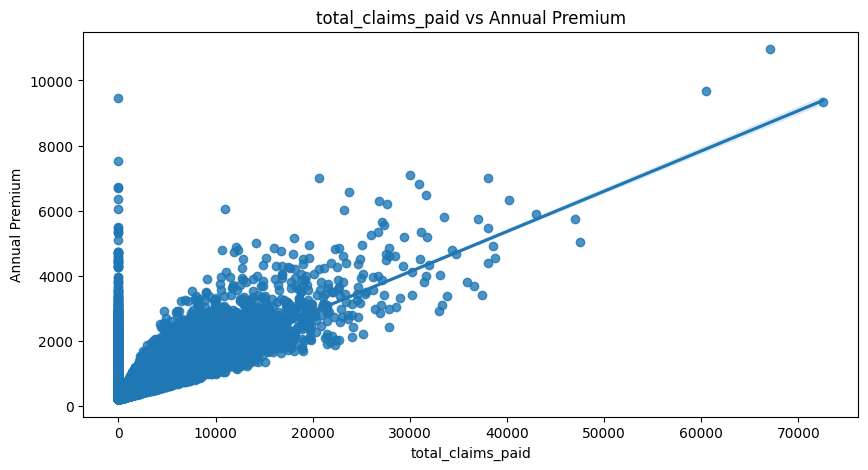

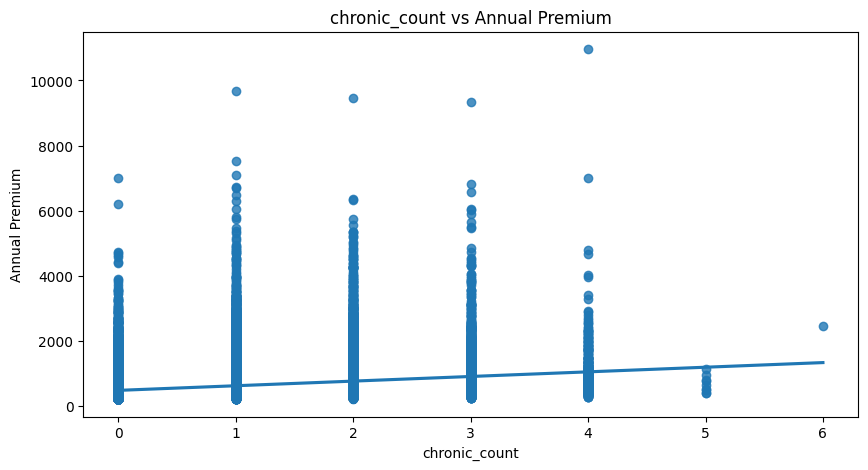

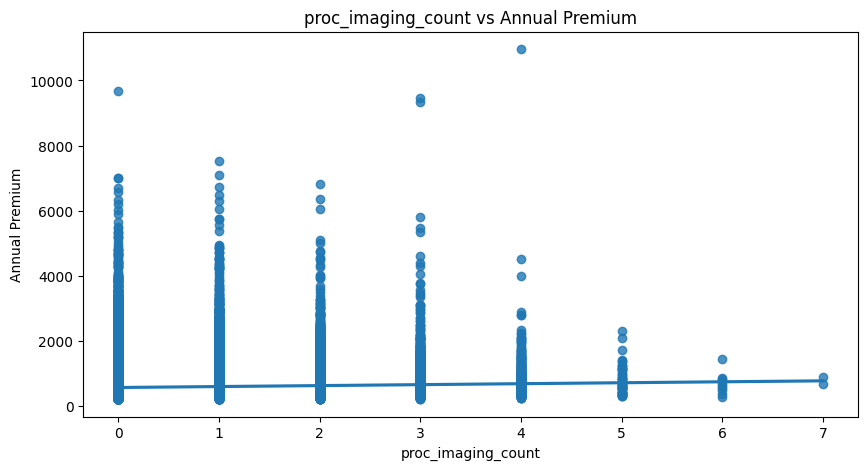

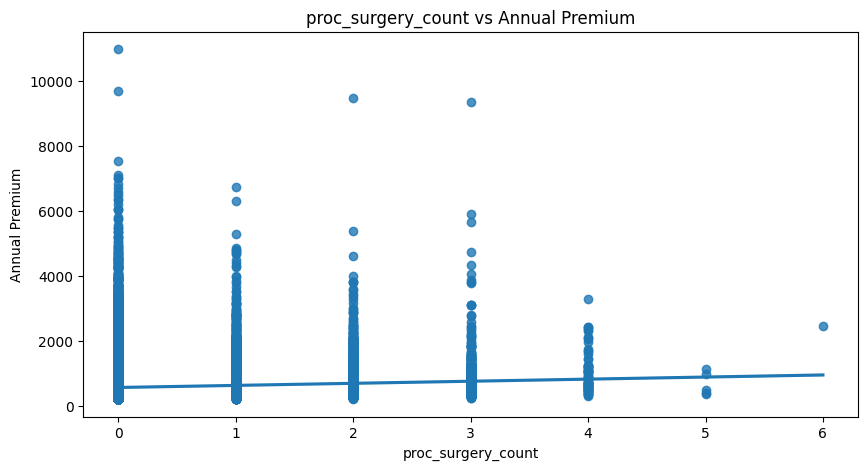

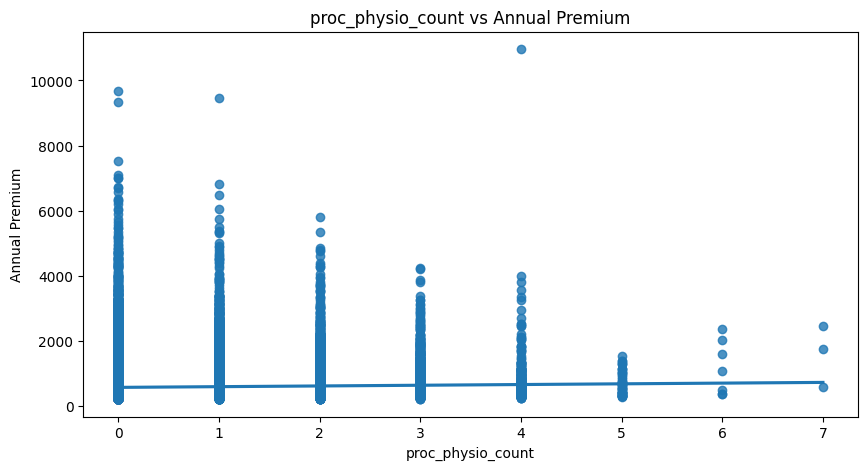

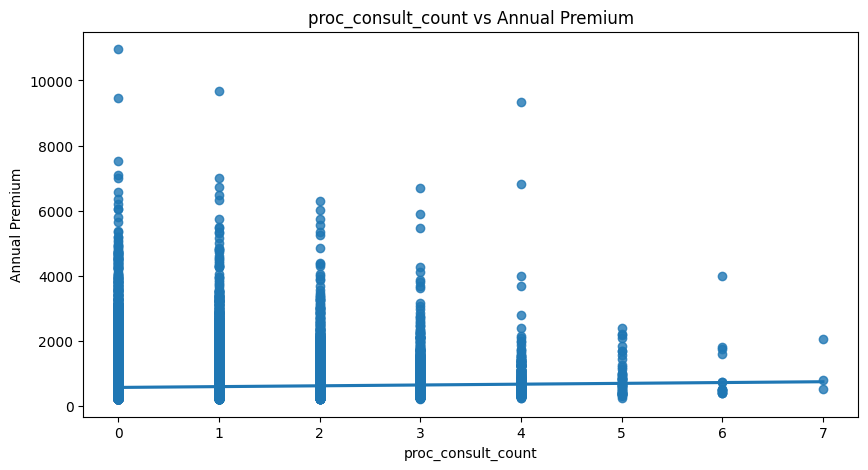

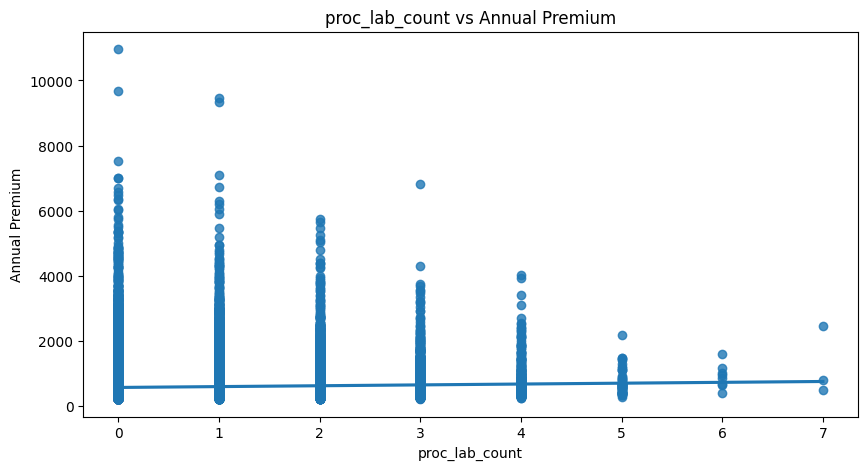

In [ ]:
numeric = data.select_dtypes(include='number')

for num_col in numeric.columns:
    if num_col in ['annual_premium','household_size','income','age']:
        continue  # skip plotting against itself

    plt.figure(figsize=(10,5))
    sns.regplot(data=numeric, x=num_col, y='annual_premium')
    plt.xlabel(num_col)
    plt.ylabel('Annual Premium')
    plt.title(f'{num_col} vs Annual Premium')
    plt.show()


## Categorical data Visualization

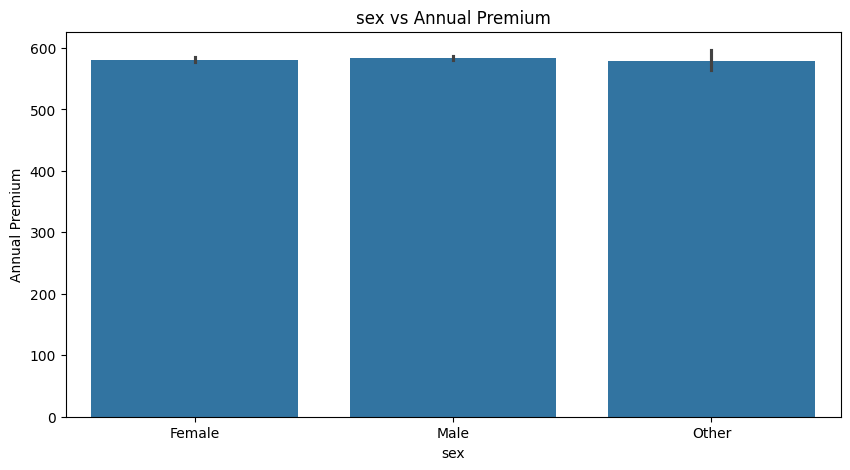

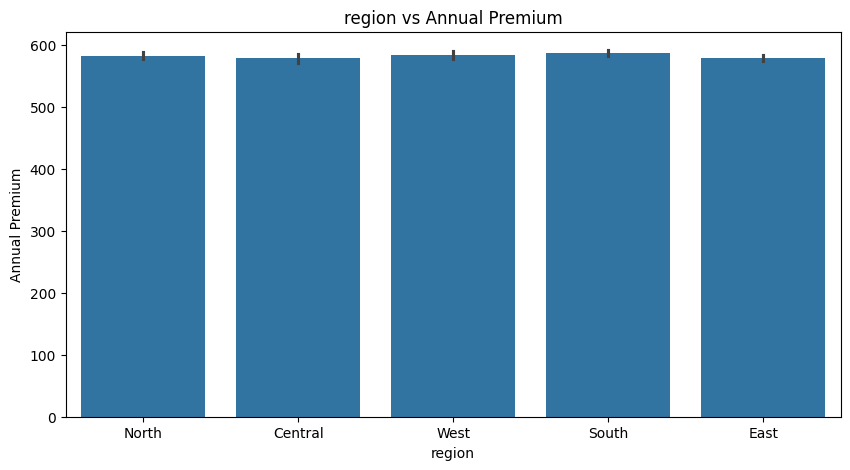

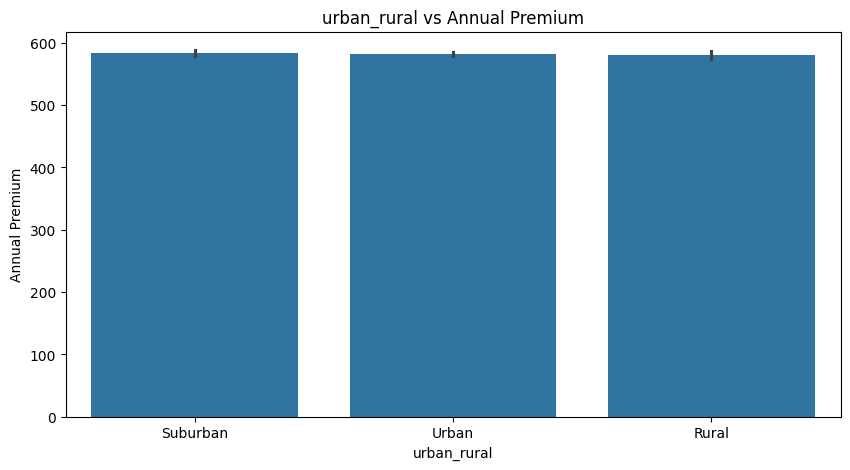

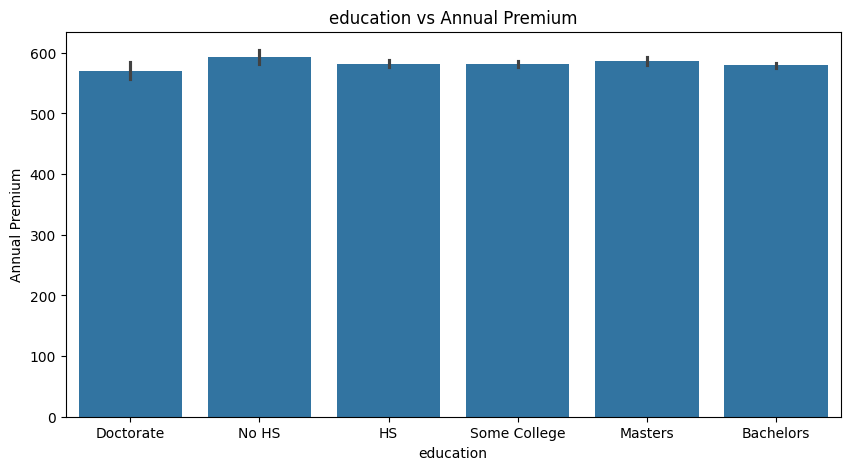

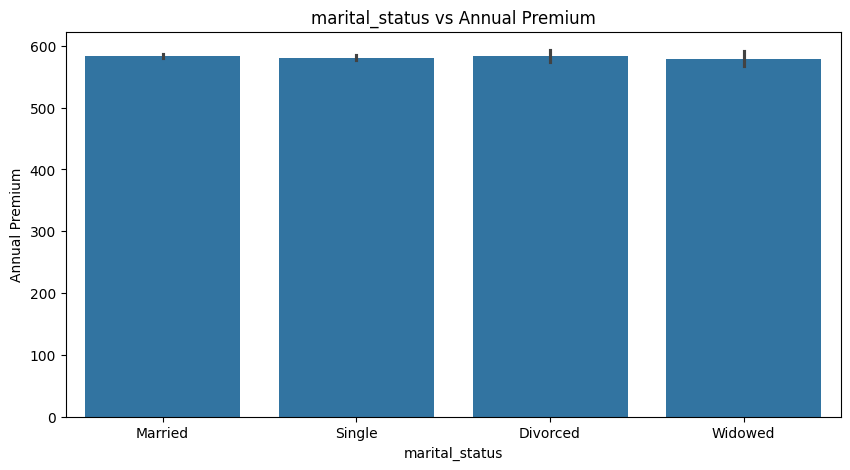

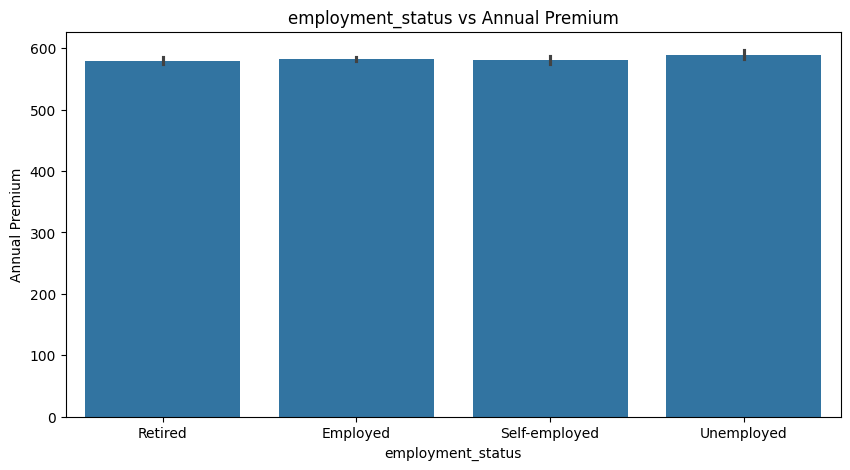

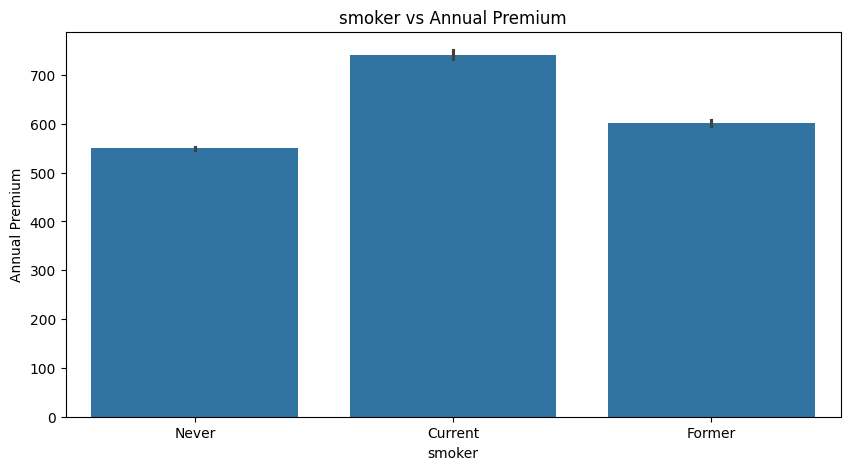

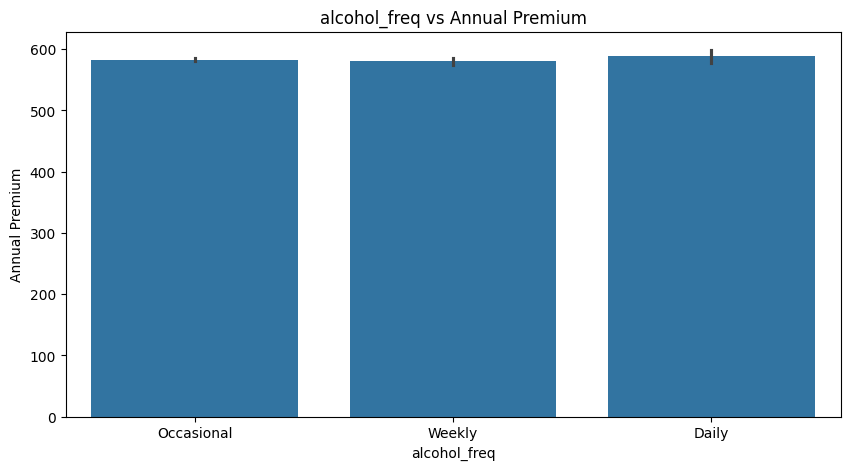

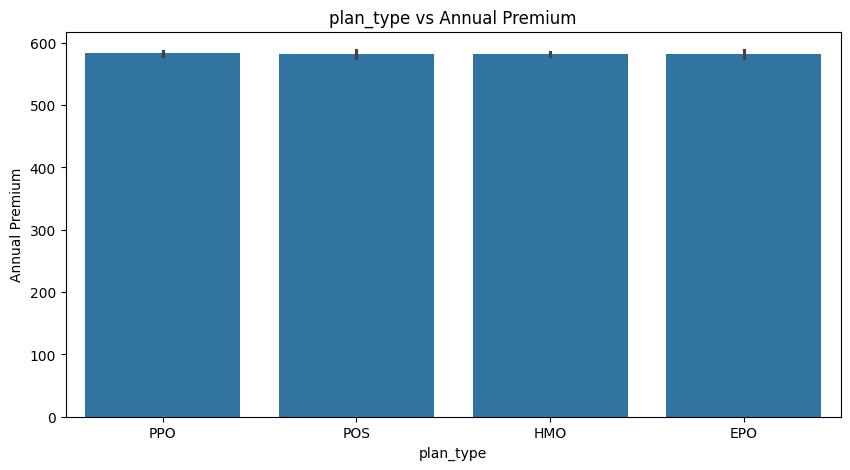

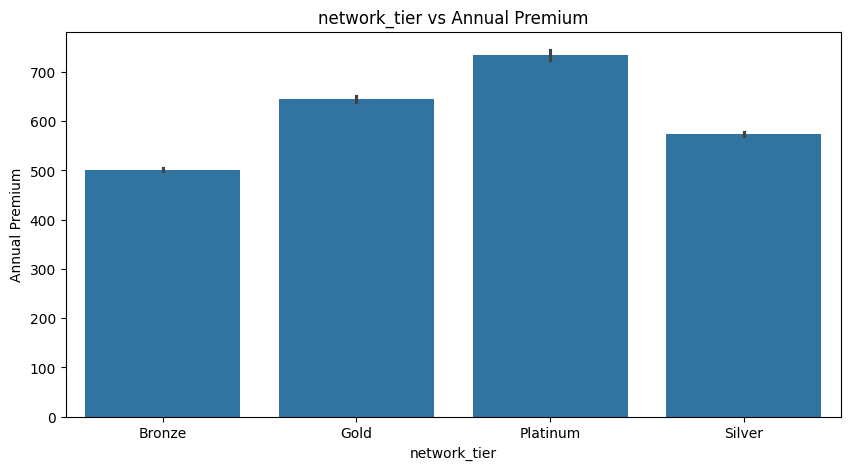

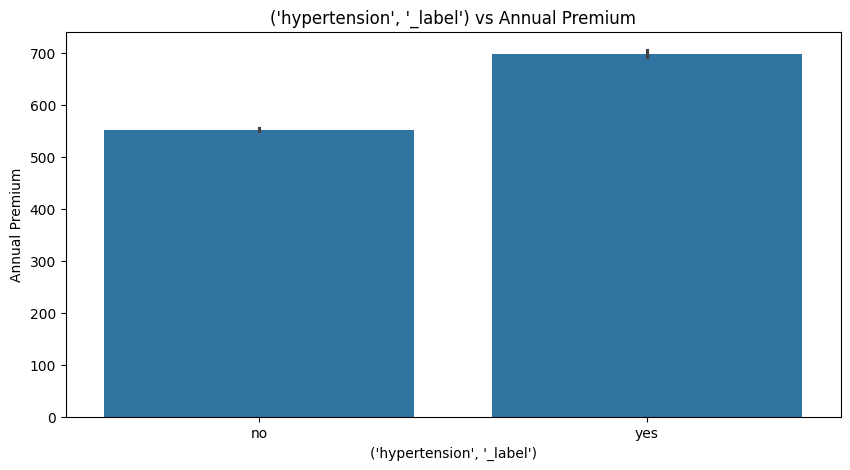

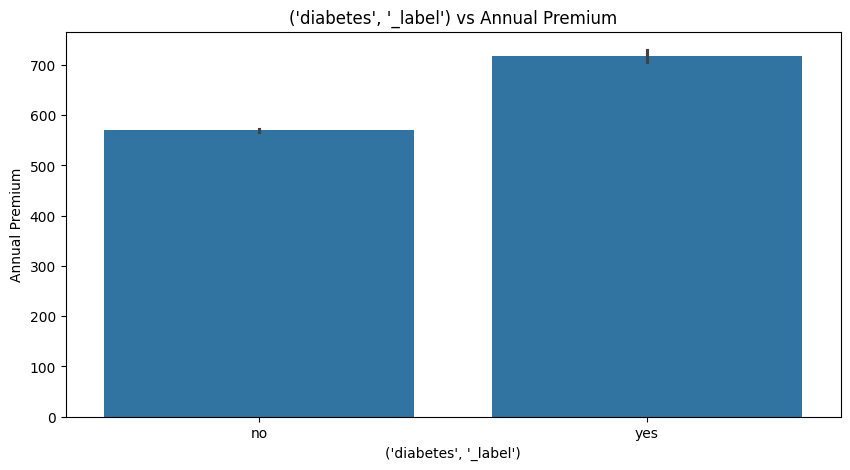

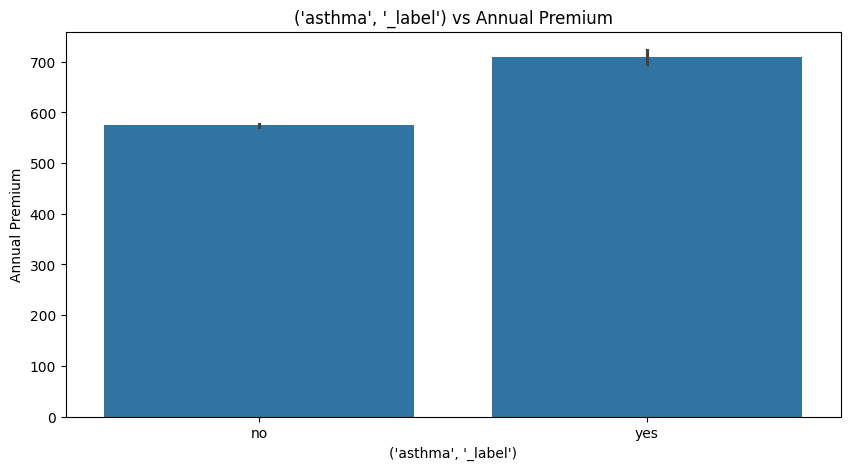

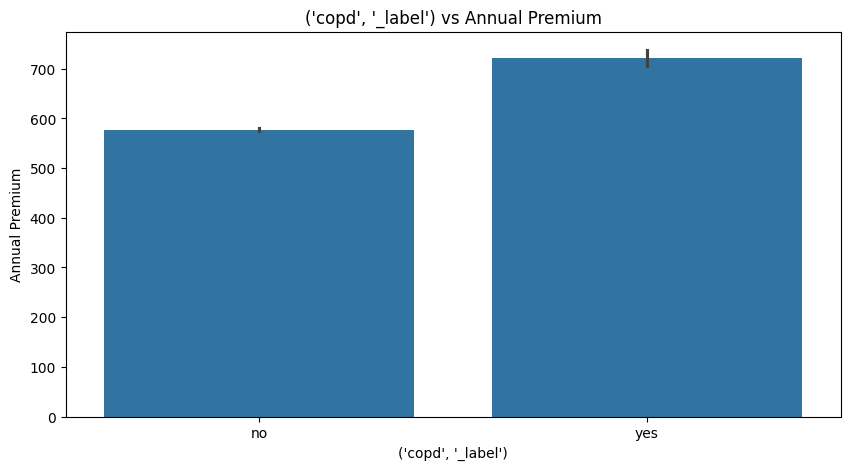

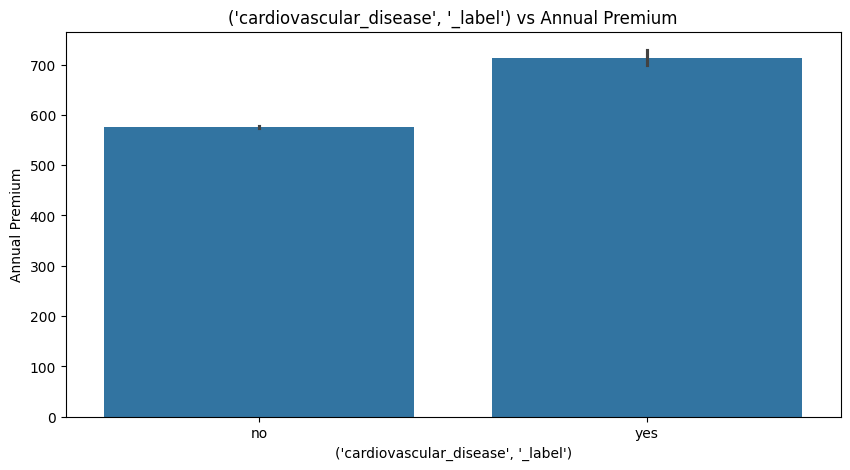

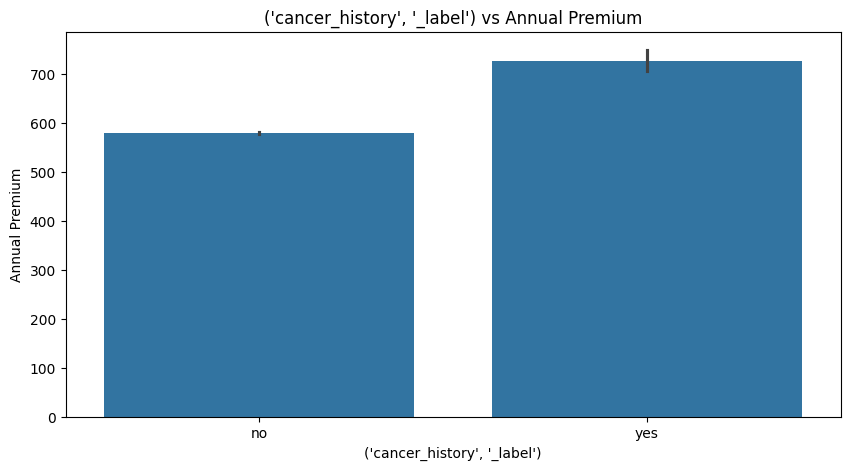

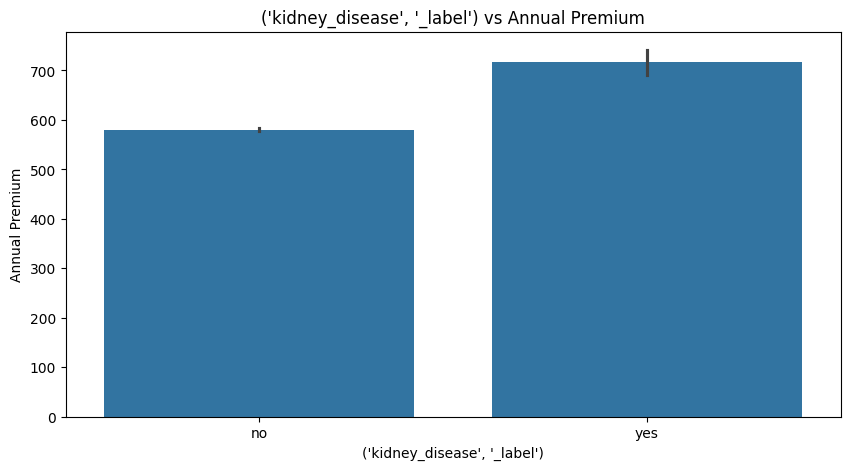

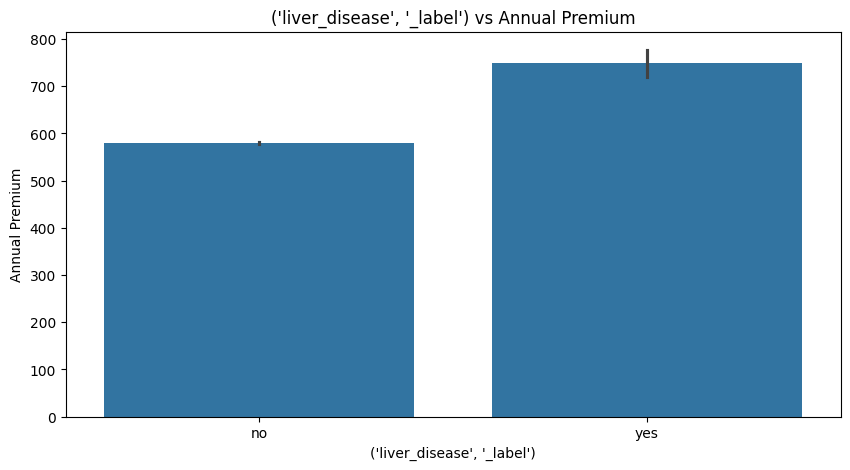

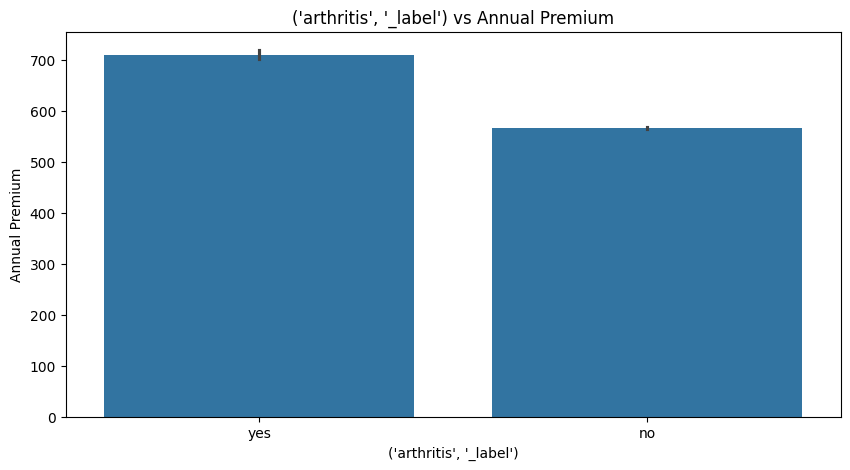

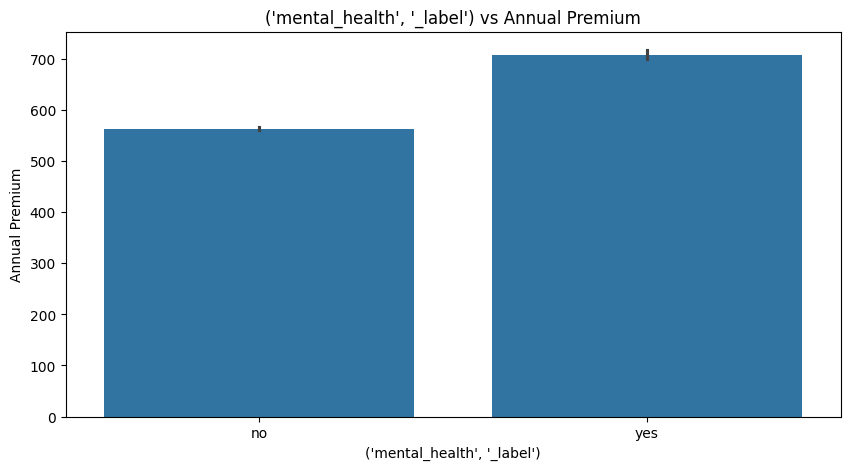

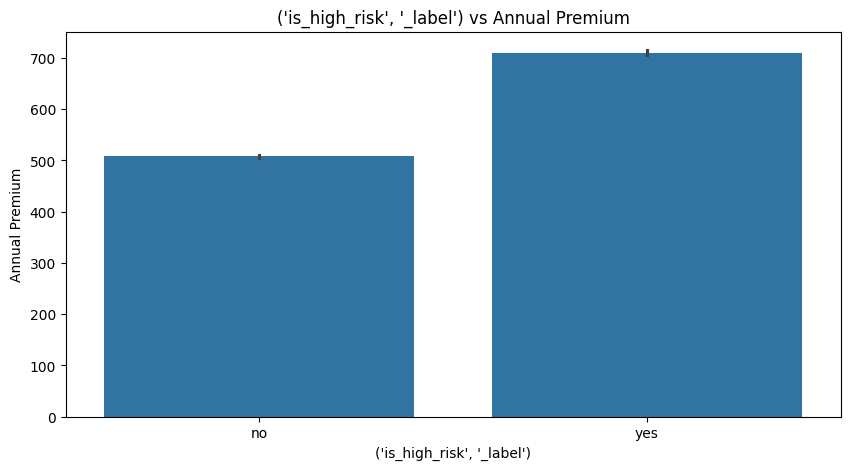

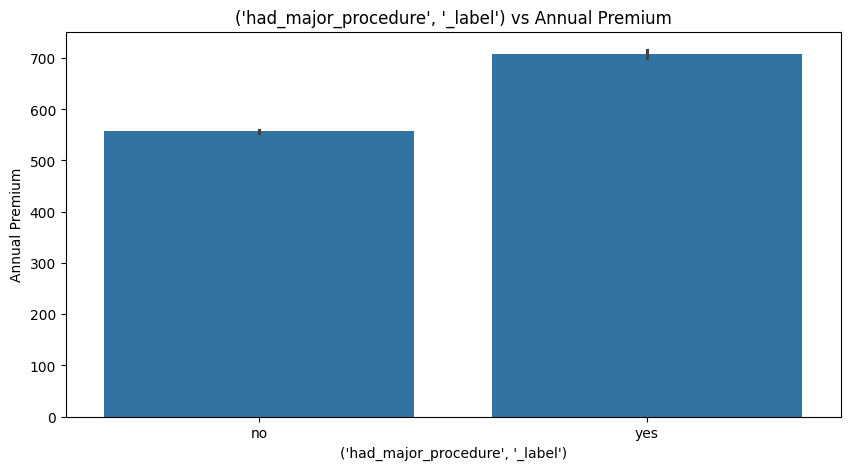

In [ ]:
categorical = data.select_dtypes(include='object')

for cat_col in categorical.columns:

    plt.figure(figsize=(10,5))
    sns.barplot(data=data, x=cat_col, y='annual_premium')
    plt.xlabel(cat_col)
    plt.ylabel('Annual Premium')
    plt.title(f'{cat_col} vs Annual Premium')
    plt.show()


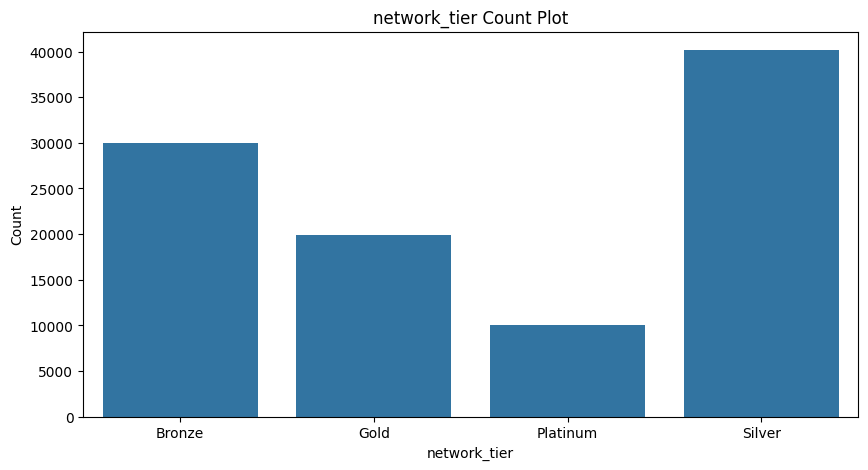

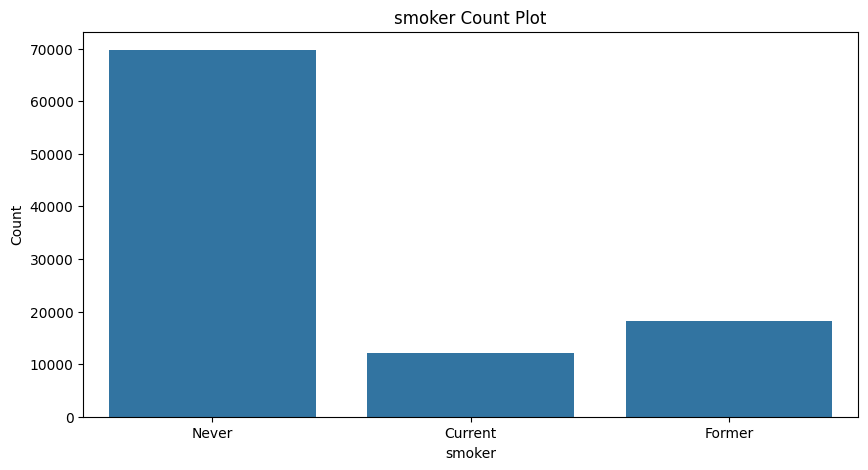

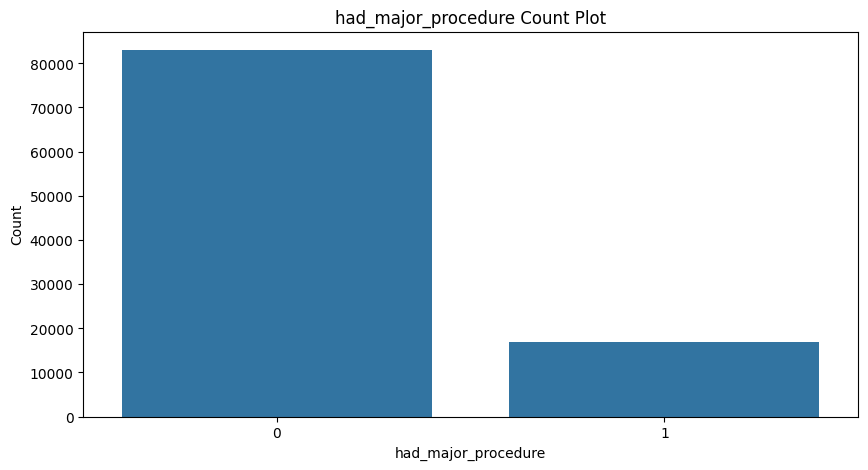

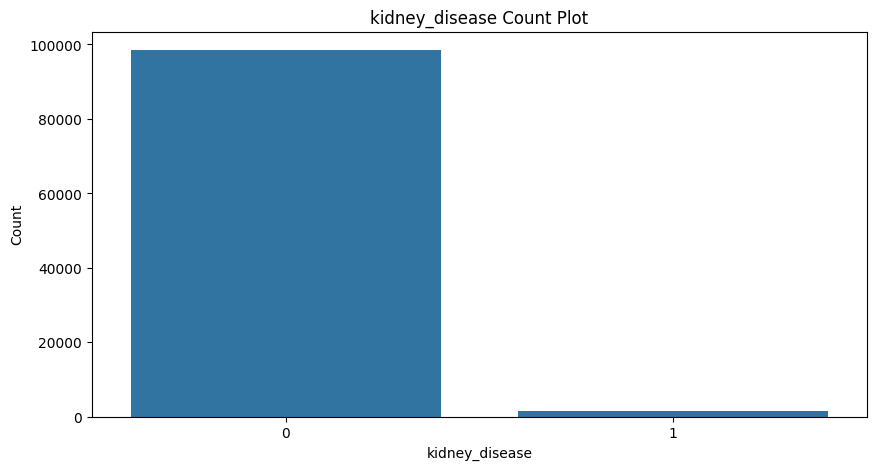

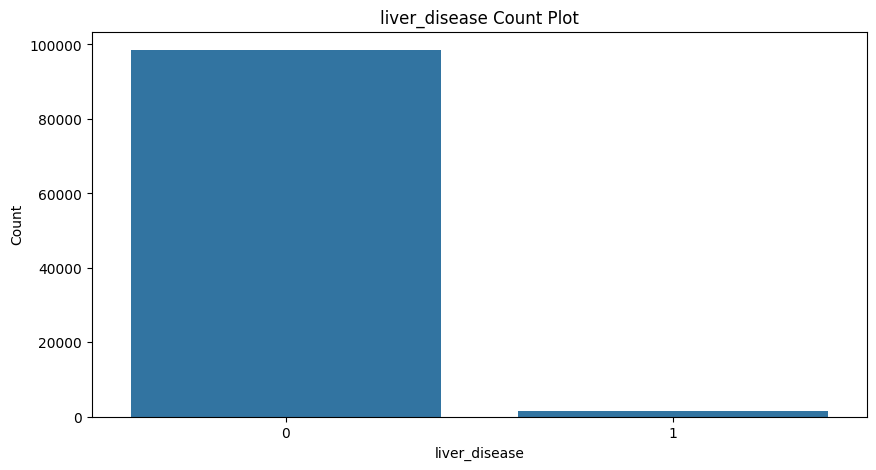

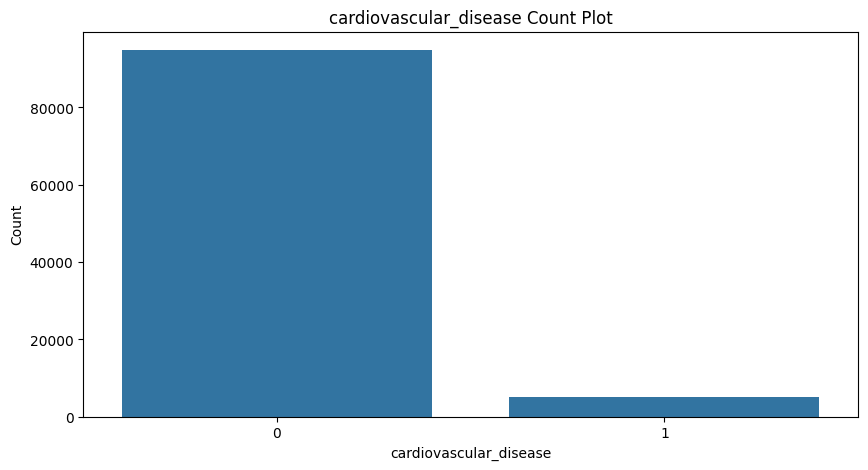

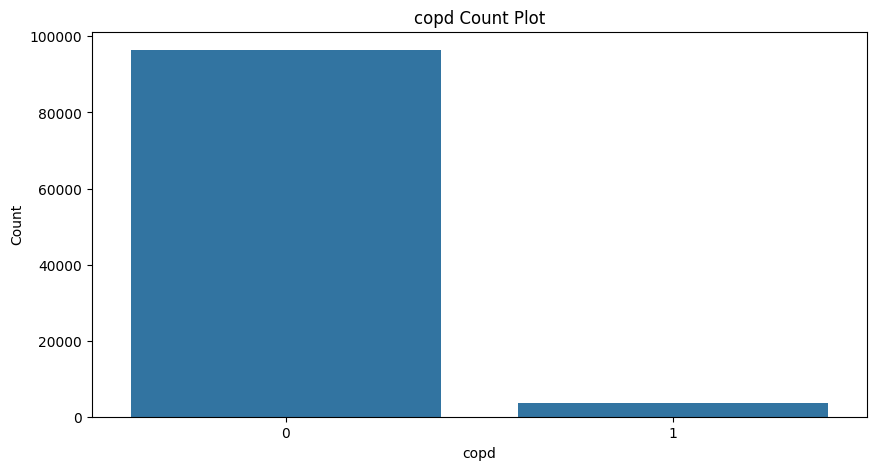

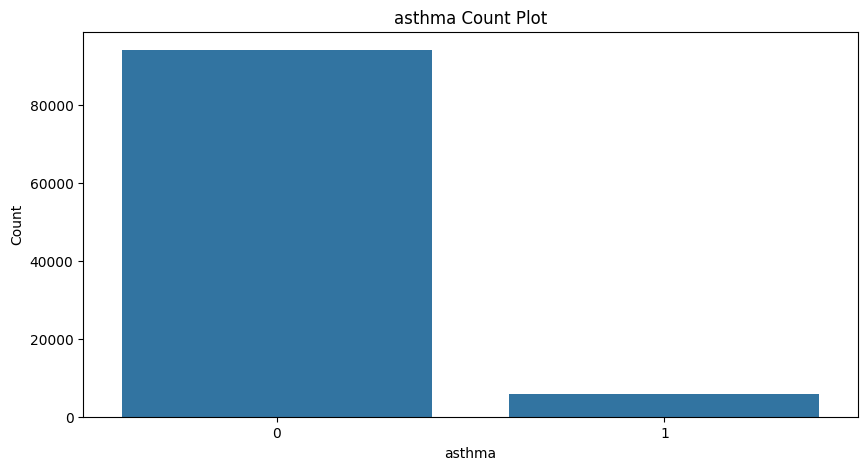

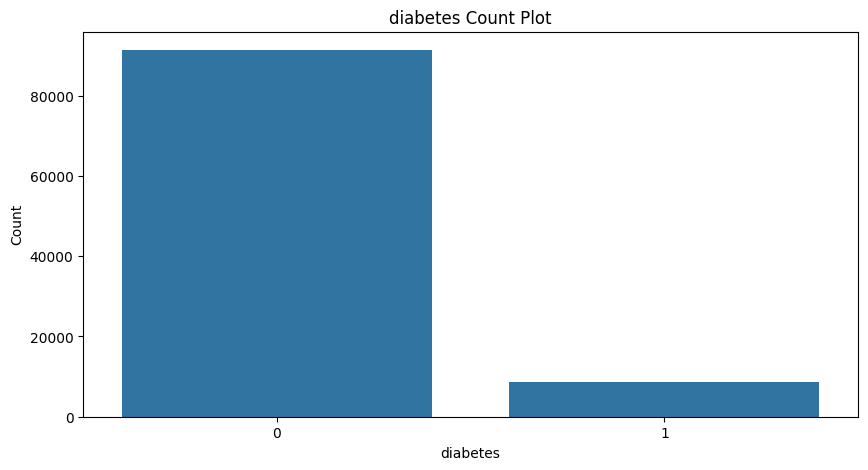

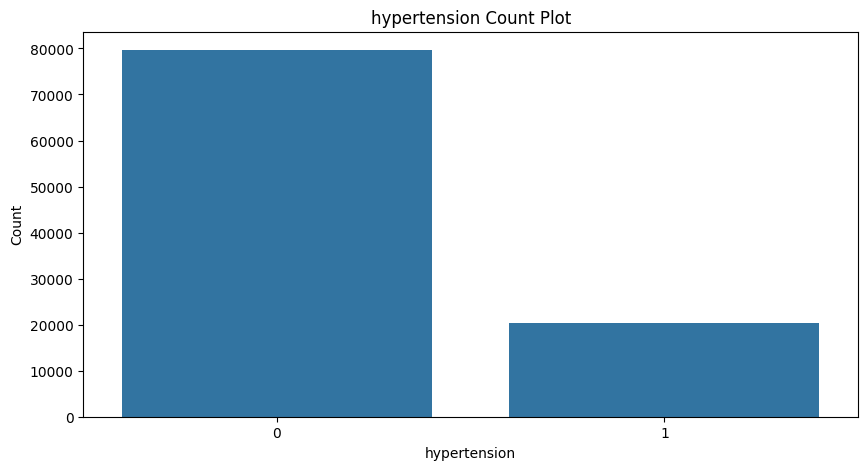

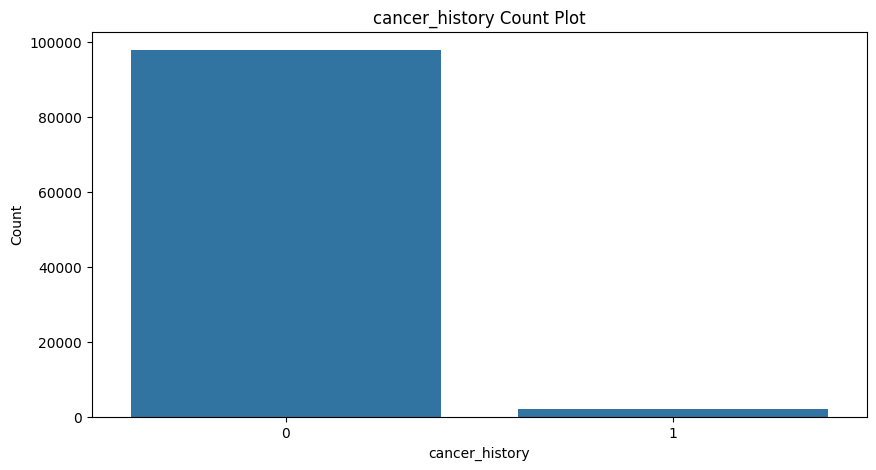

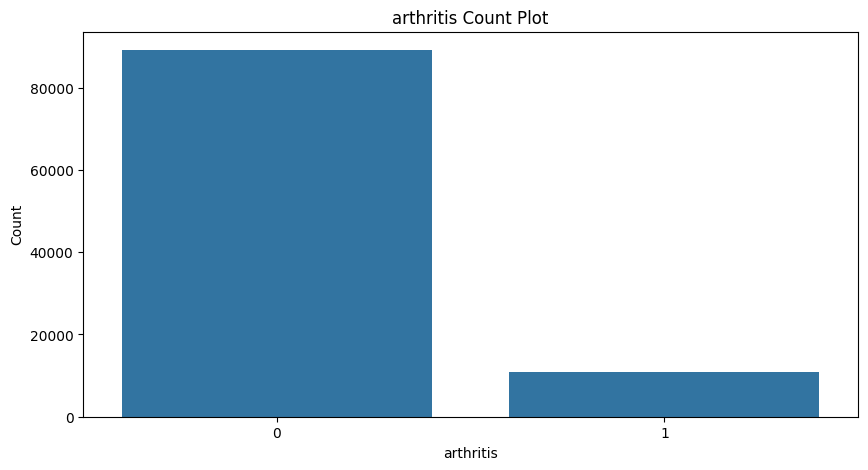

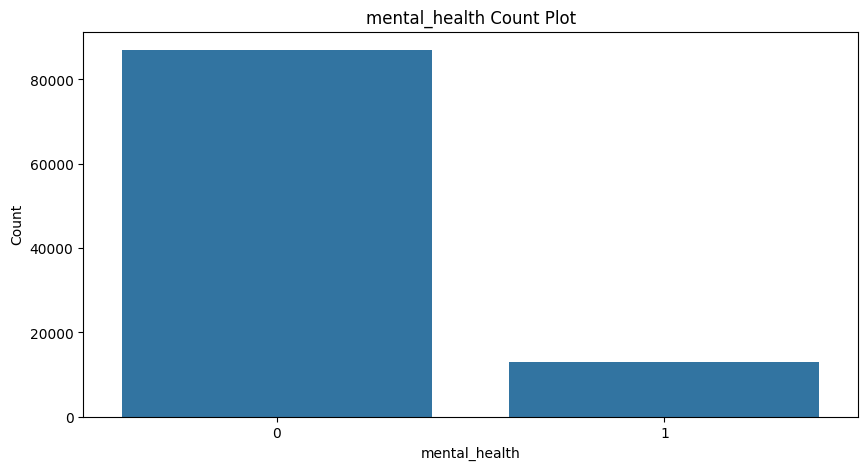

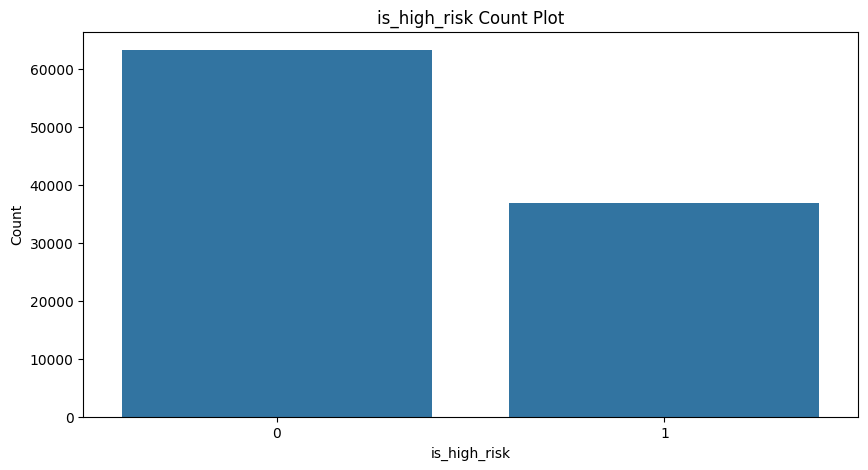

In [ ]:
categorical = data[[
    'network_tier',
    'smoker',
    'had_major_procedure',
    'kidney_disease',
    'liver_disease',
    'cardiovascular_disease',
    'copd',
    'asthma',
    'diabetes',
    'hypertension',
    'cancer_history',
    'arthritis',
    'mental_health',
    'is_high_risk'
]]

for cat_col in categorical.columns:

    plt.figure(figsize=(10,5))
    sns.countplot(data=data, x=cat_col)
    plt.xlabel(cat_col)
    plt.ylabel('Count')
    plt.title(f'{cat_col} Count Plot')
    plt.show()


# **Feature engineering and selection**

In [ ]:
categorical.head()

,network_tier,smoker,had_major_procedure,kidney_disease,liver_disease,cardiovascular_disease,copd,asthma,diabetes,hypertension,cancer_history,arthritis,mental_health,is_high_risk
0,Bronze,Never,0,0,0,0,0,0,0,0,0,1,0,0
1,Gold,Never,0,0,0,0,0,0,0,0,0,1,1,1
2,Platinum,Never,0,0,0,0,0,0,0,1,1,0,1,1
3,Silver,Never,0,0,0,0,0,0,1,0,0,0,0,0
4,Platinum,Never,0,0,0,0,0,0,0,1,0,1,0,1


In [ ]:


binary_cols = [
    "had_major_procedure",
    "kidney_disease",
    "liver_disease",
    "cardiovascular_disease",
    "copd",
    "asthma",
    "diabetes",
    "hypertension",
    "cancer_history",
    "arthritis",
    "mental_health",
    "is_high_risk",
]

# convert to numeric 0/1 then to Int8
data[binary_cols] = data[binary_cols].apply(
    lambda s: pd.to_numeric(s, errors="coerce")
).astype("Int8")


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 66 columns):
 #   Column                            Non-Null Count   Dtype  
---  ------                            --------------   -----  
 0   person_id                         100000 non-null  int64  
 1   age                               100000 non-null  int64  
 2   sex                               100000 non-null  object 
 3   region                            100000 non-null  object 
 4   urban_rural                       100000 non-null  object 
 5   income                            100000 non-null  float64
 6   education                         100000 non-null  object 
 7   marital_status                    100000 non-null  object 
 8   employment_status                 100000 non-null  object 
 9   household_size                    100000 non-null  int64  
 10  dependents                        100000 non-null  int64  
 11  bmi                               100000 non-null  fl

# **1. Pick a target**

In [ ]:
target = "annual_premium"

x = data.drop(columns=[target])
y = data[target]

In [ ]:
# Drop the labe
label_col = [col for col in x.columns if '_label' in col]
x = x.drop(columns=label_col)


In [ ]:
cat_col = x.select_dtypes(include='object').columns.tolist()
cat_col

['sex',
 'region',
 'urban_rural',
 'education',
 'marital_status',
 'employment_status',
 'smoker',
 'alcohol_freq',
 'plan_type',
 'network_tier']

# **Fitting the model**

In [ ]:
# Splitting thedataset into training and testin
X_train,X_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)



# **Encoding Categorical data**

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ('cat',OneHotEncoder(handle_unknown='ignore',sparse_output=False),cat_col)
    ],
    remainder='passthrough'
)


# **Modeling**

In [ ]:
# Fit only on training data
X_train_enc = preprocessor.fit_transform(X_train)

# Transform test data using same preprocessor
X_test_enc = preprocessor.transform(X_test)

# Fit model on encoded training data
model = LinearRegression()# Fit only on training data
X_train_enc = preprocessor.fit_transform(X_train)

# Transform test data using same preprocessor
X_test_enc = preprocessor.transform(X_test)
model.fit(X_train_enc, y_train)


LinearRegression()

# ***Making prediction***

In [ ]:

# Predict on encoded test data
y_pred = model.predict(X_test_enc)


# **Model Evaluation**

In [ ]:
# mean absolut error (MAE)
mae = mean_absolute_error(y_test,y_pred)
print(f'Mean Absolute Error: {mae}')

Mean Absolute Error: 0.030058014592227594


In [ ]:
train = X_train.copy()
train[target] = y_train

numeric_train = train.select_dtypes(include=['int64','float64','Int8'])
corr = numeric_train.corr()[target].sort_values(ascending=False)
print(corr.head(10))


annual_premium                 1.000000
monthly_premium                1.000000
annual_medical_cost            0.965355
total_claims_paid              0.721702
avg_claim_amount               0.615001
risk_score                     0.295900
chronic_count                  0.287666
is_high_risk                   0.243533
days_hospitalized_last_3yrs    0.218634
hospitalizations_last_3yrs     0.198362
Name: annual_premium, dtype: float64


In [ ]:
leaky_cols = [
    'monthly_premium',
    'annual_medical_cost',
    'total_claims_paid',
    'avg_claim_amount'
]

X_train = X_train.drop(columns=leaky_cols)
X_test = X_test.drop(columns=leaky_cols)


In [ ]:
# Fit on new X_train
X_train_enc = preprocessor.fit_transform(X_train)
X_test_enc = preprocessor.transform(X_test)


In [ ]:
model = LinearRegression()
model.fit(X_train_enc, y_train)
y_pred = model.predict(X_test_enc)

In [ ]:
mae = mean_absolute_error(y_test, y_pred)
print("Mean Absolute Error:", mae)

Mean Absolute Error: 218.46374072039566
